# Test de précision du modèle int8 : détection de "talky" en fenêtre glissante

Ce notebook évalue la capacité du modèle **quantifié int8** à détecter le mot "talky" lorsqu'il est prononcé au sein d'une phrase plus longue (et non isolé), en utilisant une inférence par **fenêtre glissante** sur tout le fichier audio.

Pour chaque fichier :
1. on découpe l'audio en fenêtres de 1s avec recouvrement,
2. on calcule le score "talky" du modèle pour chaque fenêtre,
3. on retient le score maximum sur le fichier,
4. on compare ce score à un seuil pour décider si "talky" a été détecté.

On calcule ensuite un **taux de détection** (sur les fichiers contenant réellement "talky") et un **taux de faux positifs** (sur les fichiers n'en contenant pas).

## 1. Configuration

À adapter selon ton environnement avant d'exécuter le notebook.

In [1]:
import os

# --- Chemins des données de test ---
TALKY_DIR = "C:\\Users\\sysadmin\\Documents\\stage\\database\\MODEL TRAINING\\db_piscine_wiener_off\\sentences\\key_words\\Jonas"          # phrases contenant "talky"
NO_TALKY_DIR = "C:\\Users\\sysadmin\\Documents\\stage\\database\\MODEL TRAINING\\db_piscine_wiener_off\\sentences\\no_key_words\\Jonas"   # phrases sans "talky"

# --- Chemins du modèle et de la config du pipeline ---
TFLITE_PATH = "C:\\Users\\sysadmin\\Documents\\stage\\Edge AI\\Final_repo_kws\\52-Hertz-KWS\\src\\models\\model_MCU\\final_model_deploy_int8.tflite"
CONFIG_YAML_PATH = "C:\\Users\\sysadmin\\Documents\\stage\\Edge AI\\Final_repo_kws\\52-Hertz-KWS\\configuration\\config.yaml"

# --- Chemin vers le package preprocessing (si non installé en editable) ---
import sys
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "C:\\Users\\sysadmin\\Documents\\stage\\Edge AI\\Final_repo_kws\\52-Hertz-KWS\\src")))

# --- Paramètres de la fenêtre glissante ---
SAMPLE_RATE = 16000
WINDOW_SEC = 1.0     # durée d'une fenêtre = durée attendue par le modèle
HOP_SEC = 0.25        # pas entre deux fenêtres (0.25s => 75% de recouvrement)

# --- Classes et seuil de décision ---
CLASSES = ["talky", "silence", "unknown"]   # doit correspondre à l'ordre utilisé à l'entraînement
TALKY_CLASS_INDEX = CLASSES.index("talky")
DETECTION_THRESHOLD = 0.5   # score au-dessus duquel on considère "talky" détecté (à ajuster à l'étape 6)

# --- Dossier de sortie ---
OUTPUT_DIR = "C:\\Users\\sysadmin\\Documents\\stage\\Edge AI\\Final_repo_kws\\52-Hertz-KWS\\resnet v2 s1\\Tests_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

## 2. Chargement du modèle et du pipeline audio

In [2]:
import numpy as np
import tensorflow as tf
from preprocessing import AudioPipeline

pipeline = AudioPipeline(CONFIG_YAML_PATH)

interpreter = tf.lite.Interpreter(model_path=TFLITE_PATH)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()[0]
output_details = interpreter.get_output_details()[0]

in_scale, in_zero_point = input_details["quantization"]
out_scale, out_zero_point = output_details["quantization"]

print(f"Entrée  : shape={input_details['shape']}, dtype={input_details['dtype']}, "
      f"scale={in_scale}, zero_point={in_zero_point}")
print(f"Sortie  : shape={output_details['shape']}, dtype={output_details['dtype']}, "
      f"scale={out_scale}, zero_point={out_zero_point}")
print(f"Classe 'talky' = index {TALKY_CLASS_INDEX} dans {CLASSES}")

Entrée  : shape=[ 1 64 50  1], dtype=<class 'numpy.int8'>, scale=0.032686252146959305, zero_point=-32
Sortie  : shape=[1 3], dtype=<class 'numpy.int8'>, scale=0.00390625, zero_point=-128
Classe 'talky' = index 0 dans ['talky', 'silence', 'unknown']


c:\Users\sysadmin\Documents\stage\Edge AI\Final_repo_kws\52-Hertz-KWS\venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


## 3. Inférence par fenêtre glissante

`sliding_window_scores` charge un fichier audio de durée quelconque, le découpe en fenêtres de `WINDOW_SEC` secondes (pas de `HOP_SEC`), et renvoie pour chaque fenêtre son timestamp de départ et le score (dé-quantifié) de la classe "talky".

In [3]:
import librosa

def load_full_audio(path, sr=SAMPLE_RATE):
    audio, _ = librosa.load(path, sr=sr, mono=True)
    return audio.astype(np.float32)


def run_inference_on_window(audio_window):
    """Prend une fenêtre audio brute (float32, longueur WINDOW_SEC*SAMPLE_RATE),
    applique le pipeline (normalisation + log-mel), quantifie, exécute l'inférence,
    et renvoie le score dé-quantifié pour chaque classe."""
    audio_norm = pipeline.normalize_audio(audio_window)
    log_mel = pipeline.extract_log_mel(audio_norm)          # (64, 50) float32

    log_mel_q = np.round(log_mel / in_scale + in_zero_point).astype(np.int8)
    log_mel_q = log_mel_q[..., np.newaxis][np.newaxis, ...]  # (1, 64, 50, 1)

    interpreter.set_tensor(input_details["index"], log_mel_q)
    interpreter.invoke()
    out_q = interpreter.get_tensor(output_details["index"])[0]  # (3,) int8

    # dé-quantization -> score approx. dans l'échelle du softmax d'origine
    scores = (out_q.astype(np.float32) - out_zero_point) * out_scale
    return scores


def sliding_window_scores(path, window_sec=WINDOW_SEC, hop_sec=HOP_SEC):
    audio = load_full_audio(path)
    window_len = int(window_sec * SAMPLE_RATE)
    hop_len = int(hop_sec * SAMPLE_RATE)

    # pad si le fichier est plus court qu'une fenêtre
    if len(audio) < window_len:
        audio = np.pad(audio, (0, window_len - len(audio)))

    results = []
    for start in range(0, len(audio) - window_len + 1, hop_len):
        window = audio[start:start + window_len]
        scores = run_inference_on_window(window)
        results.append({
            "start_sec": start / SAMPLE_RATE,
            "talky_score": float(scores[TALKY_CLASS_INDEX]),
        })

    # s'assurer de couvrir la toute fin du fichier même si elle ne tombe pas sur un hop exact
    if (len(audio) - window_len) % hop_len != 0:
        window = audio[-window_len:]
        scores = run_inference_on_window(window)
        results.append({
            "start_sec": (len(audio) - window_len) / SAMPLE_RATE,
            "talky_score": float(scores[TALKY_CLASS_INDEX]),
        })

    return results

### Vérification rapide sur un seul fichier

Avant de lancer l'évaluation complète, on vérifie que le score "talky" monte bien à un moment du fichier pour un exemple positif connu.

In [4]:
import glob

example_files = glob.glob(os.path.join(TALKY_DIR, "*.wav"))
assert len(example_files) > 0, "Aucun fichier trouvé dans TALKY_DIR, vérifie le chemin."

example_path = example_files[0]
example_scores = sliding_window_scores(example_path)

for r in example_scores:
    print(f"t={r['start_sec']:.2f}s  score_talky={r['talky_score']:.3f}")

max_score = max(r["talky_score"] for r in example_scores)
print(f"\nScore max sur le fichier : {max_score:.3f}")

t=0.00s  score_talky=0.285
t=0.25s  score_talky=0.301
t=0.50s  score_talky=0.395
t=0.75s  score_talky=0.324
t=1.00s  score_talky=0.320
t=1.25s  score_talky=0.320
t=1.50s  score_talky=0.293
t=1.75s  score_talky=0.250
t=2.00s  score_talky=0.344
t=2.25s  score_talky=0.418
t=2.50s  score_talky=0.305
t=2.75s  score_talky=0.293
t=3.00s  score_talky=0.293
t=3.25s  score_talky=0.359
t=3.50s  score_talky=0.363
t=3.75s  score_talky=0.293
t=4.00s  score_talky=0.320
t=4.25s  score_talky=0.301
t=4.50s  score_talky=0.305
t=4.75s  score_talky=0.309
t=5.00s  score_talky=0.305
t=5.25s  score_talky=0.293
t=5.50s  score_talky=0.336
t=5.75s  score_talky=0.262
t=6.00s  score_talky=0.203
t=6.25s  score_talky=0.203
t=6.50s  score_talky=0.191
t=6.75s  score_talky=0.258
t=7.00s  score_talky=0.238
t=7.25s  score_talky=0.250
t=7.45s  score_talky=0.215

Score max sur le fichier : 0.418


### Visualisation du score au cours du temps (exemple)

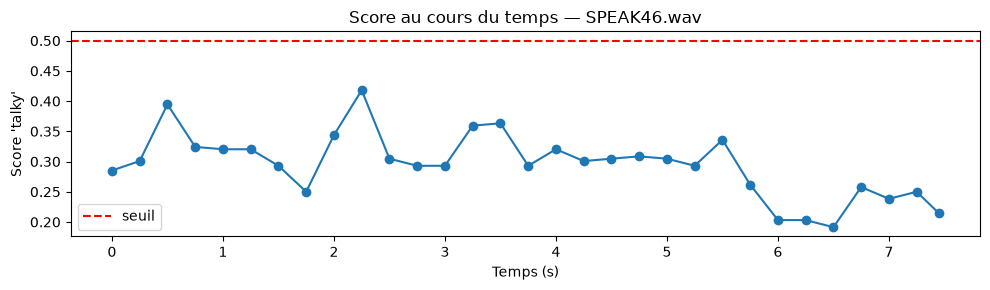

In [5]:
import matplotlib.pyplot as plt

times = [r["start_sec"] for r in example_scores]
scores = [r["talky_score"] for r in example_scores]

plt.figure(figsize=(10, 3))
plt.plot(times, scores, marker="o")
plt.axhline(DETECTION_THRESHOLD, color="red", linestyle="--", label="seuil")
plt.xlabel("Temps (s)")
plt.ylabel("Score 'talky'")
plt.title(f"Score au cours du temps — {os.path.basename(example_path)}")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "example_sliding_window_score.png"))
plt.show()

## 4. Détection au niveau fichier

On résume chaque fichier par son **score maximum** sur toutes les fenêtres. Le fichier est considéré comme "talky détecté" si ce score dépasse `DETECTION_THRESHOLD`.

In [6]:
def evaluate_file(path, threshold=DETECTION_THRESHOLD):
    results = sliding_window_scores(path)
    max_score = max(r["talky_score"] for r in results)
    detected = max_score >= threshold
    return max_score, detected

## 5. Évaluation complète sur les deux dossiers

In [7]:
import pandas as pd

def evaluate_directory(directory, ground_truth_label):
    files = sorted(glob.glob(os.path.join(directory, "*.wav")))
    rows = []
    for path in files:
        max_score, detected = evaluate_file(path)
        rows.append({
            "file": os.path.basename(path),
            "ground_truth": ground_truth_label,   # 1 = contient talky, 0 = ne contient pas talky
            "max_score": max_score,
            "detected": int(detected),
        })
    return rows

rows = []
rows += evaluate_directory(TALKY_DIR, ground_truth_label=1)
rows += evaluate_directory(NO_TALKY_DIR, ground_truth_label=0)

df = pd.DataFrame(rows)
df.to_csv(os.path.join(OUTPUT_DIR, "precision_talky_results.csv"), index=False)
df

,file,ground_truth,max_score,detected
0,SPEAK46.wav,1,0.417969,0
1,SPEAK47.wav,1,0.382812,0
2,SPEAK48.wav,1,0.371094,0
3,SPEAK49.wav,1,0.390625,0
4,SPEAK50.wav,1,0.433594,0
5,SPEAK51.wav,1,0.417969,0
6,SPEAK52.wav,1,0.390625,0
7,SPEAK53.wav,1,0.414062,0
8,SPEAK54.wav,1,0.425781,0
9,SPEAK55.wav,1,0.390625,0


### Métriques au seuil actuel

In [8]:
positives = df[df["ground_truth"] == 1]
negatives = df[df["ground_truth"] == 0]

recall = positives["detected"].mean()               # taux de détection sur les vrais positifs
false_positive_rate = negatives["detected"].mean()  # taux de fausses détections

tp = (positives["detected"] == 1).sum()
fn = (positives["detected"] == 0).sum()
fp = (negatives["detected"] == 1).sum()
tn = (negatives["detected"] == 0).sum()

precision = tp / (tp + fp) if (tp + fp) > 0 else float("nan")

print(f"Seuil utilisé        : {DETECTION_THRESHOLD}")
print(f"Fichiers 'talky'     : {len(positives)}  (TP={tp}, FN={fn})")
print(f"Fichiers 'no talky'  : {len(negatives)}  (TN={tn}, FP={fp})")
print(f"Recall (détection)   : {recall:.3f}")
print(f"Faux positifs (FPR)  : {false_positive_rate:.3f}")
print(f"Précision            : {precision:.3f}")

Seuil utilisé        : 0.5
Fichiers 'talky'     : 30  (TP=0, FN=30)
Fichiers 'no talky'  : 30  (TN=30, FP=0)
Recall (détection)   : 0.000
Faux positifs (FPR)  : 0.000
Précision            : nan


## 6. Choix du seuil optimal — courbe précision/rappel

On balaie plusieurs seuils sur le `max_score` pour voir l'effet sur le recall / la précision, et repérer un seuil offrant un bon compromis (ex. via le F1-score).

In [9]:
thresholds = np.linspace(0.0, 1.0, 101)
metrics = []

for t in thresholds:
    det_pos = (positives["max_score"] >= t)
    det_neg = (negatives["max_score"] >= t)

    tp_t = det_pos.sum()
    fn_t = (~det_pos).sum()
    fp_t = det_neg.sum()
    tn_t = (~det_neg).sum()

    recall_t = tp_t / (tp_t + fn_t) if (tp_t + fn_t) > 0 else 0
    precision_t = tp_t / (tp_t + fp_t) if (tp_t + fp_t) > 0 else 0
    f1_t = (2 * precision_t * recall_t / (precision_t + recall_t)
            if (precision_t + recall_t) > 0 else 0)
    fpr_t = fp_t / (fp_t + tn_t) if (fp_t + tn_t) > 0 else 0

    metrics.append({"threshold": t, "recall": recall_t, "precision": precision_t,
                     "f1": f1_t, "fpr": fpr_t})

metrics_df = pd.DataFrame(metrics)
best_row = metrics_df.loc[metrics_df["f1"].idxmax()]
print("Meilleur seuil (max F1) :")
print(best_row)

Meilleur seuil (max F1) :
threshold    0.340000
recall       1.000000
precision    0.508475
f1           0.674157
fpr          0.966667
Name: 34, dtype: float64


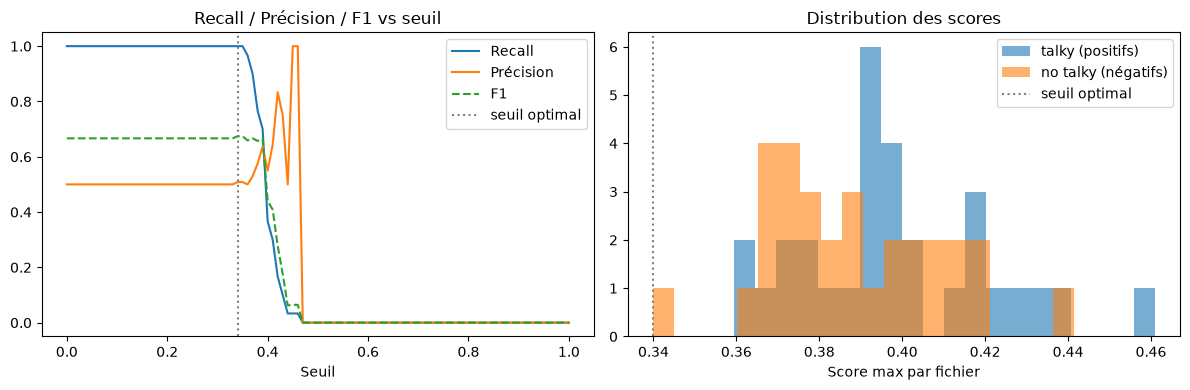

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(metrics_df["threshold"], metrics_df["recall"], label="Recall")
axes[0].plot(metrics_df["threshold"], metrics_df["precision"], label="Précision")
axes[0].plot(metrics_df["threshold"], metrics_df["f1"], label="F1", linestyle="--")
axes[0].axvline(best_row["threshold"], color="gray", linestyle=":", label="seuil optimal")
axes[0].set_xlabel("Seuil")
axes[0].set_title("Recall / Précision / F1 vs seuil")
axes[0].legend()

axes[1].hist(positives["max_score"], bins=20, alpha=0.6, label="talky (positifs)")
axes[1].hist(negatives["max_score"], bins=20, alpha=0.6, label="no talky (négatifs)")
axes[1].axvline(best_row["threshold"], color="gray", linestyle=":", label="seuil optimal")
axes[1].set_xlabel("Score max par fichier")
axes[1].set_title("Distribution des scores")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "precision_talky_threshold_analysis.png"))
plt.show()

## 7. Résumé final

Récapitulatif à conserver comme référence de performance du modèle int8 en conditions réelles (mot caché dans une phrase).

In [11]:
summary = {
    "n_files_talky": len(positives),
    "n_files_no_talky": len(negatives),
    "threshold_used": DETECTION_THRESHOLD,
    "recall_at_used_threshold": recall,
    "fpr_at_used_threshold": false_positive_rate,
    "best_threshold_by_f1": best_row["threshold"],
    "recall_at_best_threshold": best_row["recall"],
    "precision_at_best_threshold": best_row["precision"],
    "f1_at_best_threshold": best_row["f1"],
}

summary_df = pd.DataFrame([summary])
summary_df.to_csv(os.path.join(OUTPUT_DIR, "precision_talky_summary.csv"), index=False)
summary_df

,n_files_talky,n_files_no_talky,threshold_used,recall_at_used_threshold,fpr_at_used_threshold,best_threshold_by_f1,recall_at_best_threshold,precision_at_best_threshold,f1_at_best_threshold
0,30,30,0.5,0.0,0.0,0.34,1.0,0.508475,0.674157
